Load and inspect

In [13]:
import pandas as pd
import numpy as np

df = pd.read_csv('hotel_bookings.csv')
print(df.shape)              # should show (119390, 32)
print(df.isnull().sum())     # check missing values per column
print(df['is_canceled'].value_counts(normalize=True))  # check class balance

(119390, 32)
hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
com

Preprocessing

In [14]:
# Drop leakage columns — these reveal the outcome directly
df = df.drop(columns=['reservation_status', 'reservation_status_date'])

# Drop 'company' — ~94% missing, not trustworthy to impute
df = df.drop(columns=['company'])

# Handle remaining missing values
df['agent'] = df['agent'].fillna(0)
df['children'] = df['children'].fillna(0)
df['country'] = df['country'].fillna('Unknown')

# Encode categorical columns
from sklearn.preprocessing import LabelEncoder
cat_cols = df.select_dtypes(include='object').columns.tolist()
encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col].astype(str))
    encoders[col] = le

X = df.drop(columns=['is_canceled'])
y = df['is_canceled']
print(X.shape)  # confirm feature count

(119390, 28)


Train/test split (80/20)

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

Train Random Forest (regularized against overfitting)

In [16]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,          # capped — prevents memorizing training data
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)

RandomForestClassifier(max_depth=15, min_samples_leaf=5, n_estimators=200,
                       n_jobs=-1, random_state=42)

Train XGBoost (regularized)

In [17]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='logloss'
)
xgb_model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None,
              num_parallel_tree=None, ...)

metrics + confusion matrix

In [18]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, confusion_matrix, classification_report)

def evaluate(model, name):
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    print(f"\n--- {name} ---")
    print("Train acc:", accuracy_score(y_train, model.predict(X_train)))
    print("Test acc: ", accuracy_score(y_test, pred))
    print("Precision:", precision_score(y_test, pred))
    print("Recall:   ", recall_score(y_test, pred))
    print("F1:       ", f1_score(y_test, pred))
    print("ROC-AUC:  ", roc_auc_score(y_test, proba))
    print("Confusion matrix:\n", confusion_matrix(y_test, pred))

evaluate(rf_model, "Random Forest")
evaluate(xgb_model, "XGBoost")


--- Random Forest ---
Train acc: 0.8838470558673256
Test acc:  0.8694195493759946
Precision: 0.8842077015966725
Recall:    0.7450537026568683
F1:        0.8086881825990919
ROC-AUC:   0.9470837757837224
Confusion matrix:
 [[14170   863]
 [ 2255  6590]]

--- XGBoost ---
Train acc: 0.880653739844208
Test acc:  0.872309238629701
Precision: 0.85549558390579
Recall:    0.7884680610514415
F1:        0.8206154027181267
ROC-AUC:   0.9488292930980522
Confusion matrix:
 [[13855  1178]
 [ 1871  6974]]


Confusion Matrix

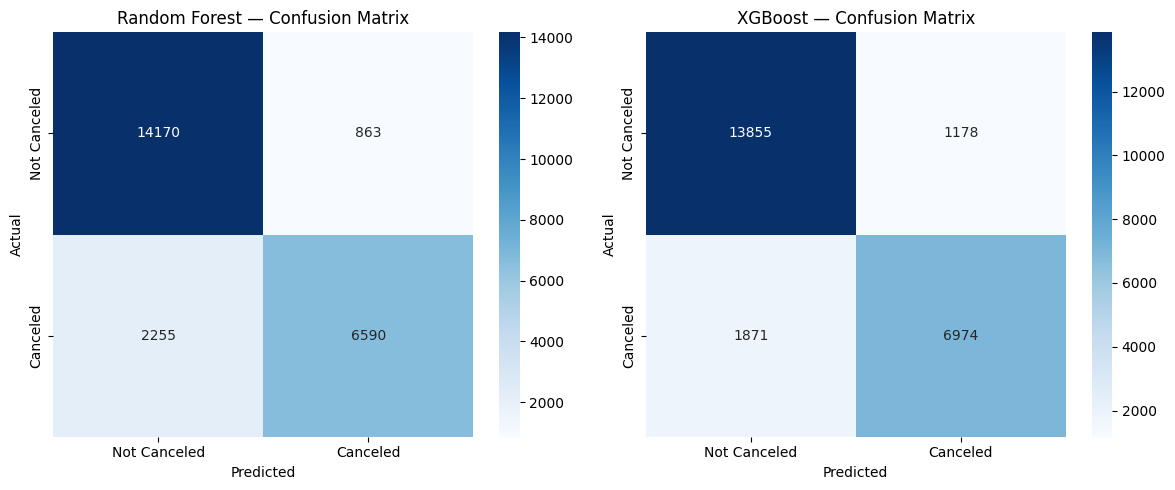

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, model, name in zip(axes, [rf_model, xgb_model], ['Random Forest', 'XGBoost']):
    pred = model.predict(X_test)
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Not Canceled', 'Canceled'],
                yticklabels=['Not Canceled', 'Canceled'])
    ax.set_title(f'{name} — Confusion Matrix')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=150)
plt.show()

Check for overfitting

In [20]:
from sklearn.model_selection import cross_val_score
cv_scores = cross_val_score(rf_model, X_train, y_train, cv=5)
print("CV scores:", cv_scores, "Mean:", cv_scores.mean())

CV scores: [0.86750772 0.87478407 0.87168883 0.8689666  0.86833839] Mean: 0.870257121853349


Save the model as .pkl

In [21]:
import joblib

joblib.dump({
    'model': xgb_model,          # changed from rf_model — XGBoost won the comparison
    'encoders': encoders,
    'feature_columns': X.columns.tolist()
}, 'course_model.pkl')

['course_model.pkl']